# Инференс финальной модели, сохранённой в директории model, на тренировочных/валидационных/тестовых данных, расчёт финальных метрик

### Назначение: 
Инференс обученной модели.
### Содержимое:
- Запуск модели, сохранённой в директории model/.
- Реализация скрипта/модуля таким образом, чтобы организаторы могли запустить ваш код в изолированном окружении.
- Расчёт финальных метрик:
    - ROC-AUC на паре ПТСР/контроль с бутстрэп-ДИ (2000 итераций);
    - сбалансированная точность;
    - специфичность на группах «нормальное старение» и «соматоформные расстройства» (доля ложноположительных ПТСР при пороге 0.5);
    - метрики отдельно по возрастным подгруппам (там, где возраст известен).
- Формирование выходного CSV с колонками subject_id, ptsd_probability.

### Виртуальная среда и установка кернела

`conda create -n check-env python=3.12.14 pip -y`

`conda activate check-env`

`python -m pip install -r requirements.txt`

`conda activate check-env`

`python -m ipykernel install --user --name check-env --display-name "Python (check-env)"`

### Импорты

In [1]:
import subprocess
import sys
from pathlib import Path
import joblib
import pandas as pd

DATA_DIR = Path("../model/neurodiagnostics-train-prep")
FEATURES_DIR = Path("../model/features")
N_WORKERS = 4

MODEL_PATH = Path("model_out.joblib")

### Запуск фича экстрактора

In [2]:
cmd = [sys.executable, "../model/feature_extraction.py", str(DATA_DIR), str(FEATURES_DIR), str(N_WORKERS)]
print("Запуск:", " ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print("=== STDERR ===")
    print(result.stderr)
    raise RuntimeError(f"feature_extraction.py упал с кодом {result.returncode}")

print("Готово. Файлы в", FEATURES_DIR, ":", list(FEATURES_DIR.iterdir()))

Запуск: /home/veronika/miniconda3/envs/check-env/bin/python ../model/feature_extraction.py ../model/neurodiagnostics-train-prep ../model/features 4
166 subjects found under ../model/neurodiagnostics-train-prep, 4 workers
  20/166
  40/166
  60/166
  80/166
  100/166
  120/166
  140/166
  160/166
saved 166 person feature vectors under ../model/features

Готово. Файлы в ../model/features : [PosixPath('../model/features/Соматоформные'), PosixPath('../model/features/Норма'), PosixPath('../model/features/ПТСР'), PosixPath('../model/features/feature_names.txt'), PosixPath('../model/features/features.csv')]


### Запуск расчета весов модели и получение метрик

In [3]:
cmd = [sys.executable, "../model/model.py", str(FEATURES_DIR), str(MODEL_PATH)]
print("Запуск:", " ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)   
if result.returncode != 0:
    print("=== STDERR ===")
    print(result.stderr)
    raise RuntimeError(f"train_top15_logreg.py упал с кодом {result.returncode}")

print("Модель сохранена:", MODEL_PATH.resolve())

Запуск: /home/veronika/miniconda3/envs/check-env/bin/python ../model/model.py ../model/features model_out.joblib
166 persons (25 PTSD) from ../model/features/features.csv, 15 features

=== LOSO cross-validation (166 folds) ===
ROC-AUC = 0.761
  @0.5 (default)         acc=0.699 precision=0.302 recall=0.760 f1=0.432

Chosen decision threshold (max F1 on LOSO OOF probabilities): 0.380
  @0.380 (chosen)        acc=0.639 precision=0.289 recall=0.960 f1=0.444

per-group mean predicted P(PTSD), LOSO out-of-fold:
  Норма           n= 67 mean_p=0.332
  ПТСР            n= 25 mean_p=0.600
  Соматоформные   n= 74 mean_p=0.407

=== Final model, fit on the FULL dataset ===
In-sample fit below is a sanity check only (NOT a generalization
estimate -- the model has already seen every one of these labels).
The LOSO numbers above are the only trustworthy performance estimate
until this saved model is scored on genuine external test data.
  in-sample @chosen thr  acc=0.645 precision=0.293 recall=0.960 f1=

### Формирование выходного CSV с колонками subject_id, ptsd_probability

In [4]:
# Загружаем сохранённый объект
artifact = joblib.load(MODEL_PATH)

model = artifact["model"]
feature_names = artifact["feature_names"]
threshold = artifact["threshold"]

print("Используемый threshold:", threshold)
print("Количество признаков:", len(feature_names))

Используемый threshold: 0.3799487985869559
Количество признаков: 15


In [5]:
# Пути
FEATURES_CSV = FEATURES_DIR / "features.csv"
OUTPUT_CSV = Path("./predictions.csv")

OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

# Загружаем признаки
df = pd.read_csv(FEATURES_CSV)

# Матрица признаков
X = df[feature_names].to_numpy(dtype="float64")

# Вероятность класса ПТСР
ptsd_probability = model.predict_proba(X)[:, 1]

# Формируем CSV с требуемыми названиями колонок
predictions = pd.DataFrame({
    "subject_id": df["person"],
    "ptsd_probability": ptsd_probability,
})

# Сохраняем без дополнительного индекса
predictions.to_csv(
    OUTPUT_CSV,
    index=False,
    encoding="utf-8"
)

print(f"CSV сохранён: {OUTPUT_CSV.resolve()}")
display(predictions.head())

CSV сохранён: /home/veronika/neurotone/atacheskaya-panika/assets/predictions.csv


,subject_id,ptsd_probability
0,КС010_19,0.737564
1,КС011_25,0.853166
2,КС012_58,0.745780
3,КС013_23,0.747088
4,КС014_22,0.576516


### Просмотр результатов обучения

In [6]:
sys.path.insert(0, "../model")  

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

import model as model  

FEATURES_DIR = "../model/features"

In [7]:
names_path = f"{FEATURES_DIR}/feature_names.txt"
csv_path = f"{FEATURES_DIR}/features.csv"

with open(names_path) as f:
    feat_names = [line.strip() for line in f if line.strip()]

df = pd.read_csv(csv_path)
X = df[feat_names].to_numpy(dtype=np.float64)
y = (df["group"] == model.PTSD_GROUP).astype(int).to_numpy()
groups = df["group"].to_numpy()

print(f"{len(y)} persons ({y.sum()} PTSD), {len(feat_names)} features")

proba = model.loso_proba(X, y) 
auc_all = roc_auc_score(y, proba)
print(f"ROC-AUC (ПТСР vs всё остальное, как в скрипте): {auc_all:.3f}")

166 persons (25 PTSD), 15 features
ROC-AUC (ПТСР vs всё остальное, как в скрипте): 0.761


In [8]:
mask_pair = np.isin(groups, [model.PTSD_GROUP, "Норма"])

def bootstrap_auc(y_, s_, n=2000, seed=0):
    y_, s_ = np.asarray(y_), np.asarray(s_)
    pos, neg = np.flatnonzero(y_ == 1), np.flatnonzero(y_ == 0)
    point = roc_auc_score(y_, s_)
    rng = np.random.default_rng(seed)
    bs = [roc_auc_score(y_[idx], s_[idx])
          for idx in (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
                      for _ in range(n))]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return point, lo, hi

auc_pair, lo_pair, hi_pair = bootstrap_auc(y[mask_pair], proba[mask_pair])
print(f"ROC-AUC (строго ПТСР vs Норма, п.6 ТЗ): {auc_pair:.3f}  95% ДИ [{lo_pair:.3f}, {hi_pair:.3f}]")
print(f"Для сравнения — AUC как в скрипте (ПТСР vs Норма+Соматоформные): {auc_all:.3f}")

ROC-AUC (строго ПТСР vs Норма, п.6 ТЗ): 0.839  95% ДИ [0.750, 0.913]
Для сравнения — AUC как в скрипте (ПТСР vs Норма+Соматоформные): 0.761


In [9]:
thr = model.best_f1_threshold(y, proba)
somato_mask = groups == "Соматоформные"

somato_proba = proba[somato_mask]
fpr_somato = (somato_proba >= thr).mean()
print(f"Порог: {thr:.3f}")
print(f"Соматоформные: n={somato_mask.sum()}, средняя P(ПТСР)={somato_proba.mean():.3f}, "
      f"доля ложноположительных при этом пороге = {fpr_somato:.3f}")

Порог: 0.380
Соматоформные: n=74, средняя P(ПТСР)=0.407, доля ложноположительных при этом пороге = 0.554


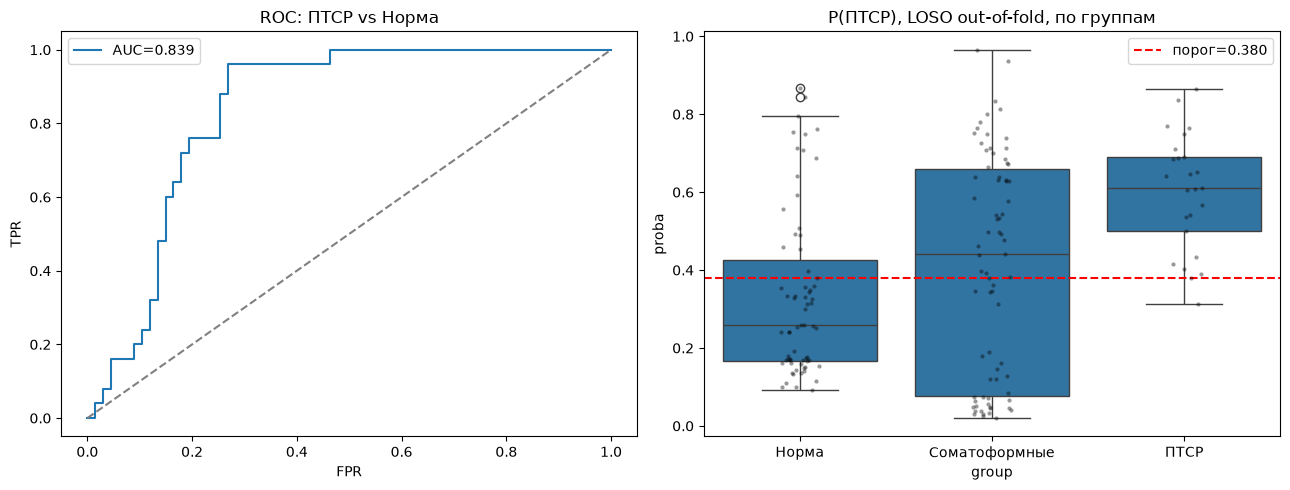

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fpr_curve, tpr_curve, _ = roc_curve(y[mask_pair], proba[mask_pair])
axes[0].plot(fpr_curve, tpr_curve, label=f"AUC={auc_pair:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[0].set_title("ROC: ПТСР vs Норма")
axes[0].legend()

plot_df = pd.DataFrame({"group": groups, "proba": proba})
sns.boxplot(data=plot_df, x="group", y="proba",
            order=["Норма", "Соматоформные", "ПТСР"], ax=axes[1])
sns.stripplot(data=plot_df, x="group", y="proba",
              order=["Норма", "Соматоформные", "ПТСР"], color="black", alpha=0.4, size=3, ax=axes[1])
axes[1].axhline(thr, color="red", ls="--", label=f"порог={thr:.3f}")
axes[1].set_title("P(ПТСР), LOSO out-of-fold, по группам")
axes[1].legend()
plt.tight_layout()
plt.show()